## **¿Qué películas y series predominan en una plataforma de streaming?**

#### **Objetivo**

El objetivo de este ejercicio es realizar un **análisis exploratorio de datos (EDA)** sobre el catálogo de Netflix para descubrir **qué tipo de contenido predomina en la plataforma** 

**Dataset:** *Netflix Movies and TV Shows* (Kaggle, Shivam Bansal) – https://www.kaggle.com/datasets/shivamb/netflix-shows
- **Cada fila representa un título** (una película o una serie) disponible en el catálogo de Netflix (datos hasta 2021).
- Columnas utilizadas: tipo de contenido (`type`), país de producción (`country`), año de lanzamiento (`release_year`), duración (`duration`) y géneros/categorías (`listed_in`).

**Preguntas que vamos a investigar:**
1. ¿Hay más películas o series?
2. ¿Qué géneros aparecen más?
3. ¿Cómo ha cambiado el número de títulos por año de lanzamiento?
4. ¿Qué países tienen más producciones en el catálogo?
5. ¿Existe relación entre el tipo de contenido (película o serie) y el género?

**¿Qué haremos a lo largo del ejercicio?**
- **Paso 1 – Comprender los datos:** cargar el CSV, ver las primeras filas, el tamaño del dataset, el significado de cada columna y sus tipos de datos.
- **Paso 2 – Revisar y limpiar:** buscar valores ausentes, duplicados y valores inconsistentes; extraer la categoría principal, agrupar los géneros en macrocategorías y separar las coproducciones por país.
- **Paso 3 – Formular preguntas:** concretar las preguntas que se pueden responder con los datos.
- **Paso 4 – Analizar:** responderlas con operaciones sencillas de pandas (recuentos, frecuencias, porcentajes, agrupaciones, mínimos, máximos y medias, tablas cruzadas).
- **Paso 5 – Visualizar:** crear gráficos con matplotlib (barras para comparar categorías y líneas para la evolución en el tiempo).
- **Paso 6 – Extraer conclusiones:** distinguir lo que muestran los datos, lo que interpretamos y lo que no podemos asegurar.

**Qué aprenderán las compañeras:** valores únicos, recuentos, datos ausentes y gráficos de barras y de líneas.


#### **Importación de librerias y carga datasets**

In [1]:
#Importación de librerias
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

## **Paso 1. Comprender los datos**

In [2]:
# Carga del archivo con pandas.
df = pd.read_csv(
    "netflix_movies.csv",
    usecols=['type', 'country', 'release_year', 'listed_in', 'duration']
)


In [3]:
#Mostrar las primeras 5 filas 
df.head()

,type,country,release_year,duration,listed_in
0,Movie,United States,2020,90 min,Documentaries
1,TV Show,South Africa,2021,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries"
2,TV Show,NaN,2021,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
3,TV Show,NaN,2021,1 Season,"Docuseries, Reality TV"
4,TV Show,India,2021,2 Seasons,"International TV Shows, Romantic TV Shows, TV ..."


In [4]:
#Cambiar los nombres de las columnas 
df.columns = ['Tipo_de_contenido','Pais_produccion', 'Año_de_lanzamiento', 'Duracion','Categoria']

In [5]:
#Comprobar cuántas filas y columnas contiene
df.shape

(8807, 5)

In [6]:
# Identificar qué representa cada fila y qué significa cada columna.
df.describe(include="all")

,Tipo_de_contenido,Pais_produccion,Año_de_lanzamiento,Duracion,Categoria
count,8807,7976,8807.000000,8804,8807
unique,2,748,NaN,220,514
top,Movie,United States,NaN,1 Season,"Dramas, International Movies"
freq,6131,2818,NaN,1793,362
mean,NaN,NaN,2014.180198,NaN,NaN
std,NaN,NaN,8.819312,NaN,NaN
min,NaN,NaN,1925.000000,NaN,NaN
25%,NaN,NaN,2013.000000,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN
75%,NaN,NaN,2019.000000,NaN,NaN


In [7]:
# Revisar los tipos de datos
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Tipo_de_contenido   8807 non-null   object
 1   Pais_produccion     7976 non-null   object
 2   Año_de_lanzamiento  8807 non-null   int64 
 3   Duracion            8804 non-null   object
 4   Categoria           8807 non-null   object
dtypes: int64(1), object(4)
memory usage: 344.2+ KB


## **Paso 2. Revisar y limpiar**

In [8]:
#Comprobar si hay valores ausentes o nulos
print(df.isna().sum()[df.isna().sum() > 0]) 


Pais_produccion    831
Duracion             3
dtype: int64


In [9]:
# Buscar posibles duplicados.
num_duplicados =df.duplicated().sum()
print(f"Hay {num_duplicados} filas duplicadas")

Hay 947 filas duplicadas


#### **Identificar valores extraños o inconsistentes y decidir si hace falta limpiar algo y explicar por qué**

In [37]:
#Elimina los nulos del dataset
df = df.dropna()


In [38]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 7973 entries, 0 to 8806
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Tipo_de_contenido    7973 non-null   object
 1   Pais_produccion      7973 non-null   object
 2   Año_de_lanzamiento   7973 non-null   int64 
 3   Duracion             7973 non-null   object
 4   Categoria            7973 non-null   object
 5   categoria_principal  7973 non-null   object
 6   genero_agrupado      7973 non-null   object
dtypes: int64(1), object(6)
memory usage: 498.3+ KB


In [13]:
df['Tipo_de_contenido'].unique()


array(['Movie', 'TV Show'], dtype=object)

In [14]:
df['Categoria'].unique()

array(['Documentaries', 'International TV Shows, TV Dramas, TV Mysteries',
       'International TV Shows, Romantic TV Shows, TV Comedies',
       'Dramas, Independent Movies, International Movies',
       'British TV Shows, Reality TV', 'Comedies, Dramas',
       'Dramas, International Movies', 'TV Comedies, TV Dramas',
       'Crime TV Shows, Spanish-Language TV Shows, TV Dramas',
       'International TV Shows, TV Action & Adventure, TV Dramas',
       'Comedies, International Movies, Romantic Movies',
       'Docuseries, International TV Shows, Reality TV', 'Comedies',
       'Horror Movies, Sci-Fi & Fantasy', 'Thrillers',
       'British TV Shows, International TV Shows, TV Comedies',
       "Kids' TV, TV Comedies", 'Action & Adventure, Dramas', "Kids' TV",
       "Kids' TV, TV Sci-Fi & Fantasy",
       'Action & Adventure, Classic Movies, Dramas',
       'Dramas, Horror Movies, Thrillers',
       'Action & Adventure, Horror Movies, Thrillers',
       'Action & Adventure', 'Dramas

In [15]:
#Extraer la categoria principal (Quedarnos con la primera categoría)
df['categoria_principal'] = df['Categoria'].str.split(',').str[0]

In [16]:
#Ver la categoria más frecuentes
df['categoria_principal'].value_counts()

categoria_principal
Dramas                          1528
Comedies                        1148
Action & Adventure               817
Documentaries                    759
International TV Shows           615
Children & Family Movies         500
Crime TV Shows                   358
Kids' TV                         318
Stand-Up Comedy                  303
Horror Movies                    262
British TV Shows                 237
Docuseries                       175
Anime Series                     154
TV Comedies                      118
International Movies             114
Reality TV                        99
Classic Movies                    80
TV Dramas                         65
Thrillers                         62
TV Action & Adventure             39
Romantic TV Shows                 32
Stand-Up Comedy & Talk Shows      31
Movies                            31
Classic & Cult TV                 21
Independent Movies                20
Anime Features                    19
Music & Musicals  

In [17]:
#Crear una nueva variable con unas 8 macrocategorías (Las más frecuentes)
def agrupar_genero(texto):

    if pd.isna(texto):
        return 'Desconocido'

    texto = texto.lower()

    if 'dramas' in texto:
        return 'Drama'

    elif 'comedies' in texto:
        return 'Comedia'

    elif 'action & adventure' in texto:
        return 'Accion y aventura'

    elif 'documentaries' in texto:
        return 'Documentales'

    elif 'international tv shows' in texto:
        return 'Serie Internacional'

    elif 'children & family movies' in texto:
        return 'Familiar'

    elif 'crime tv shows' in texto:
        return 'Crimen'

    else:
        return 'Otros'


df['genero_agrupado'] = df['Categoria'].apply(agrupar_genero)

In [18]:
df['genero_agrupado'].unique()

array(['Documentales', 'Drama', 'Comedia', 'Otros', 'Serie Internacional',
       'Accion y aventura', 'Familiar', 'Crimen'], dtype=object)

In [19]:
df['Pais_produccion'].unique()


array(['United States', 'South Africa', 'India',
       'United States, Ghana, Burkina Faso, United Kingdom, Germany, Ethiopia',
       'United Kingdom', 'Germany, Czech Republic', 'Mexico', 'Turkey',
       'Australia', 'United States, India, France', 'Finland',
       'China, Canada, United States',
       'South Africa, United States, Japan', 'Nigeria', 'Japan',
       'Spain, United States', 'France', 'Belgium',
       'United Kingdom, United States', 'United States, United Kingdom',
       'France, United States', 'South Korea', 'Spain',
       'United States, Singapore', 'United Kingdom, Australia, France',
       'United Kingdom, Australia, France, United States',
       'United States, Canada', 'Germany, United States',
       'South Africa, United States', 'United States, Mexico',
       'United States, Italy, France, Japan',
       'United States, Italy, Romania, United Kingdom',
       'Australia, United States', 'Argentina, Venezuela',
       'United States, United Kingdom,

In [20]:
#Separar todas las coproducciones (Porque una película contará para los tres paises)
paises = (
    df['Pais_produccion']
    .str.split(',')
    .explode()
    .str.strip()
)

In [21]:
paises.value_counts().head(20)

Pais_produccion
United States     3687
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
China              162
Australia          160
Egypt              117
Turkey             113
Hong Kong          105
Nigeria            103
Italy              100
Brazil              97
Argentina           91
Belgium             90
Name: count, dtype: int64

#### **Decisiones de limpieza**

- **Valores ausentes:** había 831 títulos sin país y 3 sin duración. Se han eliminado las filas con nulos (`dropna`), quedando 7.973 títulos.
- **Duplicados:** `duplicated()` detecta 947 filas repetidas, pero **no son títulos duplicados**: solo hemos cargado 5 columnas (sin el título), así que dos películas distintas pueden coincidir en tipo, país, año, duración y género. Por eso **no se eliminan**.
- **Géneros:** la columna de categorías puede tener varios géneros separados por comas. Para contar, nos quedamos con la **categoría principal** (la primera) y creamos una variable con **macrocategorías** (`genero_agrupado`).
- **Países:** las coproducciones tienen varios países en la misma celda. Las separamos con `split` + `explode` para que cada país cuente una vez por título.

 ##  **Paso 3. Formular preguntas**

| Nº | Pregunta | Columna(s) | Operación de pandas | Gráfico |
|---|---|---|---|---|
| 1 | ¿Hay más películas o series? | `Tipo_de_contenido` | `value_counts()` | Barras |
| 2 | ¿Qué géneros aparecen más? | `categoria_principal` | `value_counts().head(10)` | Barras horizontales |
| 3 | ¿Cómo ha cambiado el número de títulos por año? | `Año_de_lanzamiento` | `groupby().size()` | Líneas |
| 4 | ¿Qué países tienen más producciones? | `paises` (coproducciones separadas) | `value_counts().head(10)` | Barras horizontales |
| 5 | ¿Existe relación entre el tipo de contenido y el género? | `Tipo_de_contenido` + `genero_agrupado` | `pd.crosstab()` | Barras apiladas |

 ##  **Paso 4. Analizar**

#### **Pregunta 1. ¿Hay más películas o series?**

In [22]:
# Recuento de títulos por tipo de contenido
conteo_tipo = df['Tipo_de_contenido'].value_counts()
print(conteo_tipo)

# Mismo recuento en porcentaje (normalize=True divide cada valor entre el total)
porcentaje_tipo = (df['Tipo_de_contenido'].value_counts(normalize=True) * 100).round(1)
print(porcentaje_tipo)

Tipo_de_contenido
Movie      5688
TV Show    2285
Name: count, dtype: int64
Tipo_de_contenido
Movie      71.3
TV Show    28.7
Name: proportion, dtype: float64


#### **Pregunta 2. ¿Qué géneros aparecen más?**

In [23]:
# Top 10 de categorías principales
top_generos = df['categoria_principal'].value_counts().head(10)
top_generos

categoria_principal
Dramas                      1528
Comedies                    1148
Action & Adventure           817
Documentaries                759
International TV Shows       615
Children & Family Movies     500
Crime TV Shows               358
Kids' TV                     318
Stand-Up Comedy              303
Horror Movies                262
Name: count, dtype: int64

In [24]:
# Top 5 de géneros separado por tipo de contenido
for tipo in df['Tipo_de_contenido'].unique():
    print(f"--- {tipo} ---")
    print(df[df['Tipo_de_contenido'] == tipo]['categoria_principal'].value_counts().head(5), "\n")

--- Movie ---
categoria_principal
Dramas                      1528
Comedies                    1148
Action & Adventure           817
Documentaries                759
Children & Family Movies     500
Name: count, dtype: int64 

--- TV Show ---
categoria_principal
International TV Shows    615
Crime TV Shows            358
Kids' TV                  318
British TV Shows          237
Docuseries                175
Name: count, dtype: int64 



#### **Pregunta 3. ¿Cómo ha cambiado el número de títulos por año?**

In [25]:
# Año más antiguo, más reciente, media y mediana del año de lanzamiento por tipo
df.groupby('Tipo_de_contenido')['Año_de_lanzamiento'].agg(['min', 'max', 'mean', 'median']).round(0)

,min,max,mean,median
Tipo_de_contenido,,,,
Movie,1942,2021,2013.0,2016.0
TV Show,1945,2021,2016.0,2018.0


In [26]:
# Número de títulos por año de lanzamiento y tipo
titulos_por_año = df.groupby(['Año_de_lanzamiento', 'Tipo_de_contenido']).size().unstack(fill_value=0)

# Nos quedamos con los años desde 2000 (antes hay muy pocos títulos)
titulos_por_año = titulos_por_año[titulos_por_año.index >= 2000]
titulos_por_año.tail(10)

Tipo_de_contenido,Movie,TV Show
Año_de_lanzamiento,,
2012,167,55
2013,212,58
2014,252,81
2015,375,140
2016,638,200
2017,729,236
2018,713,325
2019,565,348
2020,461,391


In [27]:
# Año con más títulos lanzados
total_por_año = df.groupby('Año_de_lanzamiento').size()
print(f"Año con más títulos: {total_por_año.idxmax()} ({total_por_año.max()} títulos)")

Año con más títulos: 2018 (1038 títulos)


#### **Pregunta 4. ¿Qué países tienen más producciones en el catálogo?**

In [28]:
# Top 10 de países (una coproducción cuenta para cada país participante)
# Quitamos posibles textos vacíos que aparecen cuando la celda termina en coma
top_paises = paises[paises != ''].value_counts().head(10)
top_paises

Pais_produccion
United States     3687
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

#### **Pregunta 5. ¿Existe relación entre el tipo de contenido y el género?**

In [29]:
# Tabla cruzada: cuántos títulos hay de cada género agrupado según el tipo
tabla_genero_tipo = pd.crosstab(df['genero_agrupado'], df['Tipo_de_contenido'])
tabla_genero_tipo

Tipo_de_contenido,Movie,TV Show
genero_agrupado,,
Accion y aventura,456,76
Comedia,1096,405
Crimen,0,74
Documentales,782,0
Drama,2317,663
Familiar,187,0
Otros,850,549
Serie Internacional,0,518


In [30]:
# Misma tabla en porcentaje por fila: ¿qué % de cada género son películas y qué % series?
tabla_genero_tipo_pct = (pd.crosstab(df['genero_agrupado'], df['Tipo_de_contenido'], normalize='index') * 100).round(1)
tabla_genero_tipo_pct.sort_values('Movie', ascending=False)

Tipo_de_contenido,Movie,TV Show
genero_agrupado,,
Documentales,100.0,0.0
Familiar,100.0,0.0
Accion y aventura,85.7,14.3
Drama,77.8,22.2
Comedia,73.0,27.0
Otros,60.8,39.2
Crimen,0.0,100.0
Serie Internacional,0.0,100.0


#### **Extra: duración media de las películas**

In [31]:
# La duración de las películas viene como texto ("90 min"), la pasamos a número
duracion_peliculas = (
    df[df['Tipo_de_contenido'] == 'Movie']['Duracion']
    .str.replace(' min', '')
    .astype(int)
)
duracion_peliculas.describe().round(1)

count    5688.0
mean      100.5
std        27.1
min         3.0
25%        88.0
50%        99.0
75%       115.0
max       312.0
Name: Duracion, dtype: float64

 ##  **Paso 5. Visualizar**

#### **Gráfico 1. Películas vs series (barras)**

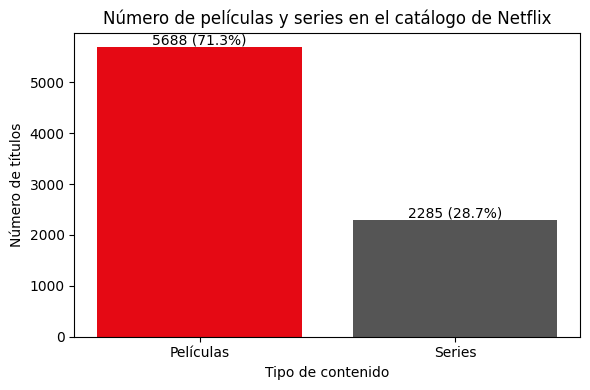

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(['Películas', 'Series'], conteo_tipo.values, color=['#E50914', '#555555'])
ax.bar_label(barras, labels=[f"{v} ({p}%)" for v, p in zip(conteo_tipo.values, porcentaje_tipo.values)])
ax.set_title('Número de películas y series en el catálogo de Netflix')
ax.set_xlabel('Tipo de contenido')
ax.set_ylabel('Número de títulos')
plt.tight_layout()
plt.show()

**¿Qué observamos?** Las películas son claramente mayoría: aproximadamente 7 de cada 10 títulos del catálogo son películas.

#### **Gráfico 2. Top 10 géneros (barras horizontales)**

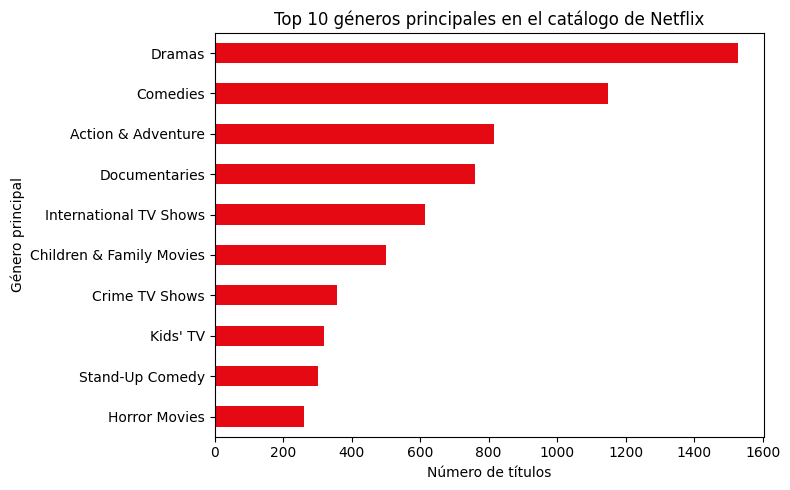

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
top_generos.sort_values().plot(kind='barh', ax=ax, color='#E50914')
ax.set_title('Top 10 géneros principales en el catálogo de Netflix')
ax.set_xlabel('Número de títulos')
ax.set_ylabel('Género principal')
plt.tight_layout()
plt.show()

**¿Qué observamos?** Dramas y comedias lideran el catálogo, seguidos de acción y aventura y documentales. El primer género propio de series (*International TV Shows*) aparece en quinta posición.

#### **Gráfico 3. Evolución del número de títulos por año (líneas)**

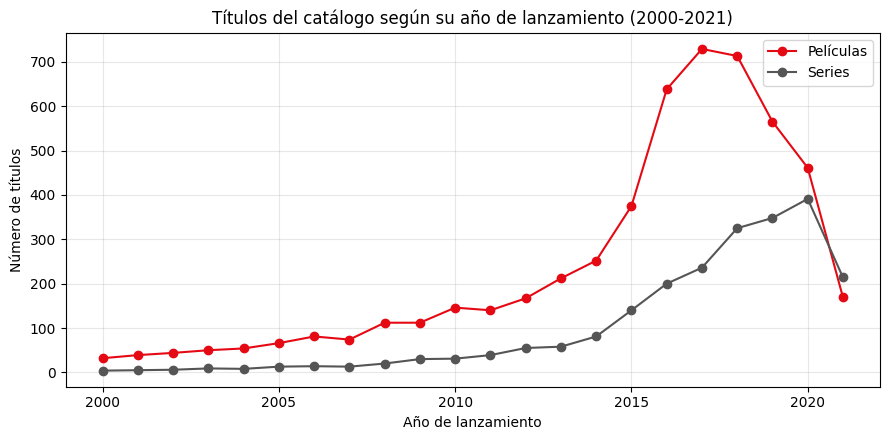

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(titulos_por_año.index, titulos_por_año['Movie'], marker='o', label='Películas', color='#E50914')
ax.plot(titulos_por_año.index, titulos_por_año['TV Show'], marker='o', label='Series', color='#555555')
ax.set_title('Títulos del catálogo según su año de lanzamiento (2000-2021)')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Número de títulos')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**¿Qué observamos?** El número de títulos crece mucho a partir de 2015 y alcanza su máximo en 2018. La caída de 2021 se explica porque los datos llegan solo hasta ese año (el año no está completo).

#### **Gráfico 4. Top 10 países productores (barras horizontales)**

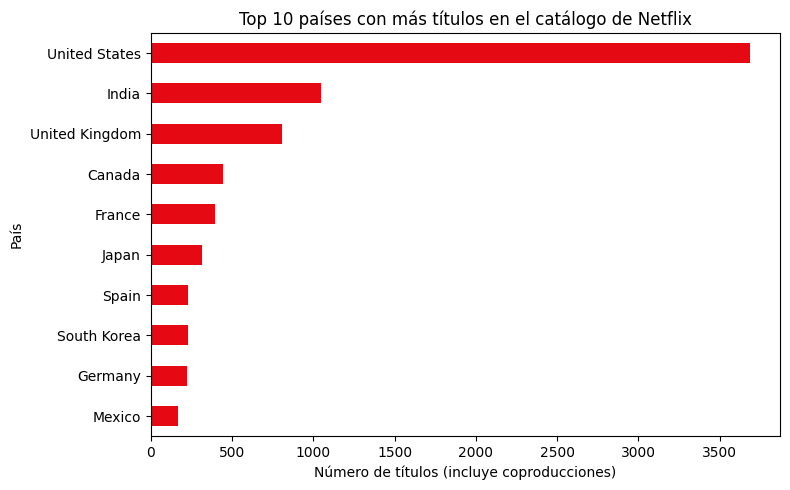

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
top_paises.sort_values().plot(kind='barh', ax=ax, color='#E50914')
ax.set_title('Top 10 países con más títulos en el catálogo de Netflix')
ax.set_xlabel('Número de títulos (incluye coproducciones)')
ax.set_ylabel('País')
plt.tight_layout()
plt.show()

**¿Qué observamos?** Estados Unidos domina con mucha diferencia (más del triple que India, el segundo). España aparece en séptima posición.

#### **Gráfico 5. Relación entre tipo de contenido y género (barras apiladas)**

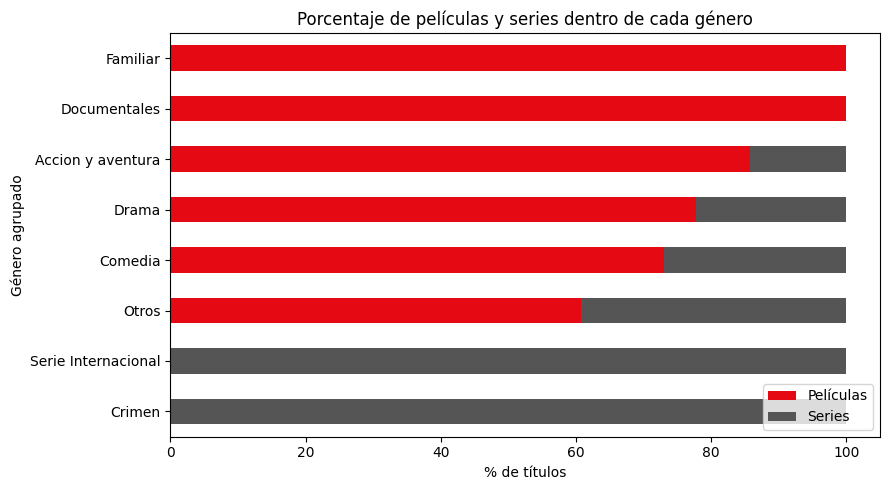

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
tabla_genero_tipo_pct.sort_values('Movie').plot(kind='barh', stacked=True, ax=ax, color=['#E50914', '#555555'])
ax.set_title('Porcentaje de películas y series dentro de cada género')
ax.set_xlabel('% de títulos')
ax.set_ylabel('Género agrupado')
ax.legend(['Películas', 'Series'], loc='lower right')
plt.tight_layout()
plt.show()

**¿Qué observamos?** Algunos géneros son casi exclusivamente de películas y otros casi exclusivamente de series, por lo que el género sí está relacionado con el tipo de contenido.

 ##  **Paso 6. Extraer conclusiones**

#### **Lo que muestran directamente los datos**
1. **Predominan las películas:** de los 7.973 títulos analizados, alrededor del **71 % son películas** y el **29 % series**.
2. **Los géneros más frecuentes** como categoría principal son **Dramas, Comedias, Acción y aventura y Documentales**.
3. **El catálogo está concentrado en títulos recientes:** el número de títulos crece con fuerza desde 2015 y el año con más lanzamientos es **2018**. La mitad de las películas son de 2016 o posteriores y la mitad de las series de 2018 o posteriores.
4. **Estados Unidos** es, con diferencia, el país con más producciones, seguido de **India** y **Reino Unido**.
5. **Tipo y género están relacionados:** hay géneros que son casi solo de películas y otros casi solo de series.
6. Las películas duran de media unos **100 minutos**.

#### **Lo que interpretamos**
- Netflix parece apostar sobre todo por contenido **reciente** y de **géneros de gran público** (drama y comedia).
- El peso de India, Japón, Corea del Sur o España sugiere una estrategia de **contenido internacional**, además del estadounidense.

#### **Lo que NO podemos asegurar**
- **No sabemos qué se ve más:** el dataset cuenta títulos, no visualizaciones ni popularidad.
- **No podemos hablar de causas:** que haya más dramas no significa que el público los prefiera (correlación ≠ causalidad).
- Los datos llegan hasta **2021** y se eliminaron los títulos sin país, por lo que el catálogo actual puede ser distinto.
- Solo usamos la **primera categoría** de cada título, así que los géneros secundarios no se cuentan.

## **Mini reto para las compañeras**

Mirando el **Gráfico 3** (evolución por año):
1. ¿En qué año se lanzaron más títulos del catálogo?
2. ¿Por qué creéis que baja tanto en 2021? ¿Significa que Netflix dejó de añadir contenido?

*Pista para la pregunta 2: pensad en hasta qué fecha llegan los datos.*